<a href="https://colab.research.google.com/github/amiiiiiitz/problem-solving/blob/main/AI-ML/ML6_PP.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
import numpy as np
import pandas as pd
import scipy.stats as stats
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries loaded successfully.")

Libraries loaded successfully.


## Problem 1: Z-Score Method (Normal Data)

**Dataset:** Age of students in a class
```python
ages = [18, 19, 20, 20, 21, 21, 22, 22, 23, 24,
        25, 26, 27, 28, 30, 32, 35, 40, 45, 70]
```

**Tasks:**
1. Calculate the mean and standard deviation of Age.
2. Compute the Z-Score for each value.
3. Identify outliers using the condition $|Z| > 3$.
4. Remove those outliers and show the new dataset length.

In [4]:
import numpy as np
import pandas as pd

# Dataset
ages = np.array([18, 19, 20, 20, 21, 21, 22, 22, 23, 24,
                 25, 26, 27, 28, 30, 32, 35, 40, 45, 70])

# 1. Calculate mean and standard deviation
mean_age = np.mean(ages)
std_age = np.std(ages)
print(f"Mean: {mean_age:.2f}")
print(f"Standard Deviation: {std_age:.2f}\n")

# 2. Compute the Z-Scores
z_scores = (ages - mean_age) / std_age
for age, z in zip(ages, z_scores):
    print(f"Age: {age:2d} -> Z-Score: {z:.2f}")

# 3. Identify outliers (|Z| > 3)
outliers = ages[np.abs(z_scores) > 3]
print(f"\nOutliers identified: {outliers}")

# 4. Remove outliers and show the new dataset length
clean_ages = ages[np.abs(z_scores) <= 3]
print(f"Original Length: {len(ages)}")
print(f"New Length: {len(clean_ages)}")

Mean: 28.40
Standard Deviation: 11.83

Age: 18 -> Z-Score: -0.88
Age: 19 -> Z-Score: -0.79
Age: 20 -> Z-Score: -0.71
Age: 20 -> Z-Score: -0.71
Age: 21 -> Z-Score: -0.63
Age: 21 -> Z-Score: -0.63
Age: 22 -> Z-Score: -0.54
Age: 22 -> Z-Score: -0.54
Age: 23 -> Z-Score: -0.46
Age: 24 -> Z-Score: -0.37
Age: 25 -> Z-Score: -0.29
Age: 26 -> Z-Score: -0.20
Age: 27 -> Z-Score: -0.12
Age: 28 -> Z-Score: -0.03
Age: 30 -> Z-Score: 0.14
Age: 32 -> Z-Score: 0.30
Age: 35 -> Z-Score: 0.56
Age: 40 -> Z-Score: 0.98
Age: 45 -> Z-Score: 1.40
Age: 70 -> Z-Score: 3.52

Outliers identified: [70]
Original Length: 20
New Length: 19


## Problem 2: IQR Method (Skewed Data)

**Dataset:** Monthly salaries (in thousand BDT)
```python
salaries = [25, 28, 30, 32, 32, 33, 35, 35, 36, 38,
            40, 42, 45, 48, 50, 55, 60, 65, 70, 80,
            120, 150, 200, 250, 500]
```

**Tasks:**
1. Calculate Q1 (25th percentile) and Q3 (75th percentile).
2. Find IQR = Q3 − Q1.
3. Calculate the lower bound and upper bound.
4. Identify outliers.
5. Cap (clip) the outliers to the bounds instead of deleting them.
6. Show the minimum and maximum values after capping.

In [5]:
# Dataset
salaries = np.array([25, 28, 30, 32, 32, 33, 35, 35, 36, 38,
                     40, 42, 45, 48, 50, 55, 60, 65, 70, 80,
                     120, 150, 200, 250, 500])

# 1. Calculate Q1 and Q3
q1 = np.percentile(salaries, 25)
q3 = np.percentile(salaries, 75)

# 2. Find IQR
iqr = q3 - q1

# 3. Calculate lower and upper bounds
lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

print(f"Q1: {q1}")
print(f"Q3: {q3}")
print(f"IQR: {iqr}")
print(f"Lower Bound: {lower_bound}")
print(f"Upper Bound: {upper_bound}\n")

# 4. Identify outliers
outliers = salaries[(salaries < lower_bound) | (salaries > upper_bound)]
print(f"Outliers: {outliers}")

# 5. Cap (clip) outliers
capped_salaries = np.clip(salaries, lower_bound, upper_bound)

# 6. Show min and max values after capping
print(f"Min value after capping: {np.min(capped_salaries)}")
print(f"Max value after capping: {np.max(capped_salaries)}")

Q1: 35.0
Q3: 70.0
IQR: 35.0
Lower Bound: -17.5
Upper Bound: 122.5

Outliers: [150 200 250 500]
Min value after capping: 25.0
Max value after capping: 122.5


## Problem 3: Choose the Right Method

### Dataset A: Exam Scores
```python
exam_scores = [55, 58, 60, 62, 65, 65, 68, 70, 72, 75,
               78, 80, 85, 90, 95, 98, 100, 100, 100, 15, 20]
```

### Dataset B: House Prices (in lakh BDT)
```python
house_prices = [30, 32, 35, 38, 40, 42, 45, 48, 50, 55,
                60, 65, 70, 80, 90, 100, 120, 150, 200,
                300, 400, 500, 800, 1000, 1200]
```

**Tasks:**
1. For Dataset A, plot a histogram (conceptually). Is the distribution normal or skewed?
2. Which method (Z-Score or IQR) would you choose for Dataset A? Why?
3. For Dataset B, which method would you choose? Why?
4. Apply the IQR method to Dataset B and count how many outliers you get.

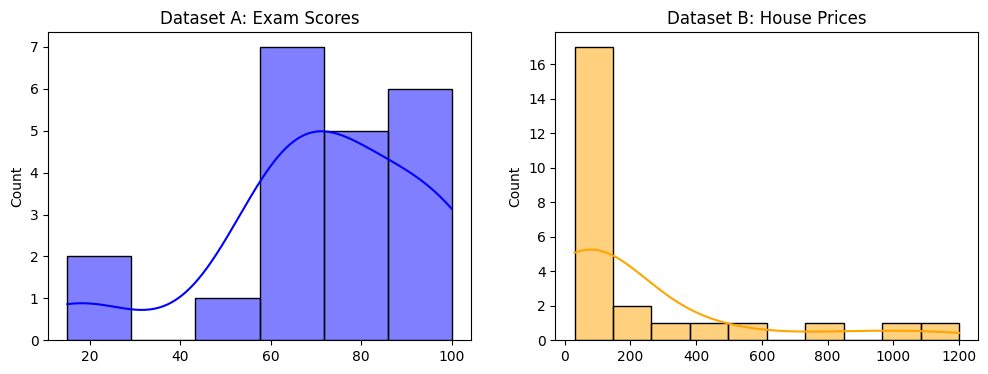

Number of outliers in Dataset B: 4
Outliers in Dataset B: [ 500  800 1000 1200]


In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

# Datasets
exam_scores = [55, 58, 60, 62, 65, 65, 68, 70, 72, 75,
               78, 80, 85, 90, 95, 98, 100, 100, 100, 15, 20]

house_prices = [30, 32, 35, 38, 40, 42, 45, 48, 50, 55,
                60, 65, 70, 80, 90, 100, 120, 150, 200,
                300, 400, 500, 800, 1000, 1200]

# Plot distributions
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(exam_scores, kde=True, ax=axes[0], color='blue')
axes[0].set_title("Dataset A: Exam Scores")

sns.histplot(house_prices, kde=True, ax=axes[1], color='orange')
axes[1].set_title("Dataset B: House Prices")
plt.show()

# IQR on Dataset B
hp_arr = np.array(house_prices)
q1_hp = np.percentile(hp_arr, 25)
q3_hp = np.percentile(hp_arr, 75)
iqr_hp = q3_hp - q1_hp
upper_hp = q3_hp + 1.5 * iqr_hp
lower_hp = q1_hp - 1.5 * iqr_hp
hp_outliers = hp_arr[(hp_arr < lower_hp) | (hp_arr > upper_hp)]

print(f"Number of outliers in Dataset B: {len(hp_outliers)}")
print(f"Outliers in Dataset B: {hp_outliers}")

### Answers for Problem 3:
1. **Dataset A Distribution:** Looking at the plot, the exam scores are **left-skewed** (negatively skewed) due to the low scores of 15 and 20 dragging the distribution down.
2. **Method for Dataset A:** **IQR** is better suited here because the data is skewed. The Z-Score method assumes a standard normal distribution and can be highly influenced by the extreme scores, distorting the mean and standard deviation.
3. **Method for Dataset B:** **IQR** is ideal for House Prices because prices are usually highly right-skewed and non-normal.
4. **Dataset B IQR Outliers:** See the output of the Python cell above (4 outliers detected: `[500, 800, 1000, 1200]`).

## Problem 4: Winsorization (Percentile Method)

**Dataset:** Product ratings (out of 10)
```python
ratings = [1, 2, 3, 4, 4, 5, 5, 5, 6, 6,
           7, 7, 8, 8, 9, 9, 10, 10, 1, 2,
           10, 10, 10, 0.5, 9.5]
```

**Tasks:**
1. Use 5% Winsorization (x = 5), meaning cap at the 5th and 95th percentiles.
2. Calculate the 5th percentile and 95th percentile.
3. Cap all values below the 5th percentile to the 5th percentile value.
4. Cap all values above the 95th percentile to the 95th percentile value.
5. Show the minimum and maximum values after Winsorization.
6. Explain why Winsorization is better than deletion in this case.

In [7]:
ratings = np.array([1, 2, 3, 4, 4, 5, 5, 5, 6, 6,
                    7, 7, 8, 8, 9, 9, 10, 10, 1, 2,
                    10, 10, 10, 0.5, 9.5])

# 2. Calculate 5th and 95th percentiles
p5 = np.percentile(ratings, 5)
p95 = np.percentile(ratings, 95)

print(f"5th Percentile: {p5}")
print(f"95th Percentile: {p95}\n")

# 3 & 4. Cap values
winsorized_ratings = np.clip(ratings, p5, p95)

# 5. Show min and max
print(f"Min value after Winsorization: {np.min(winsorized_ratings)}")
print(f"Max value after Winsorization: {np.max(winsorized_ratings)}")

5th Percentile: 1.0
95th Percentile: 10.0

Min value after Winsorization: 1.0
Max value after Winsorization: 10.0


### Answers for Problem 4 (Task 6):
* **Why Winsorization is better than deletion:** Product ratings are naturally bounded between 0 and 10. Deleting extreme ratings (like 0.5 or 10) removes valid consumer feedback. Winsorization limits the impact of extreme outliers while retaining the presence of the observations in our statistical analysis.

## Problem 5: Mixed Methods – Compare Z-Score & IQR on the Same Data

**Dataset:** Product ratings (out of 10)
```python
ratings = [12, 15, 18, 20, 22, 22, 23, 24, 25, 25,
           26, 27, 28, 30, 32, 35, 38, 40, 45, 50,
           55, 60, 65, 70, 80, 90, 100, 120, 150,
           200, 500, 1000, 2000]
```

**Tasks:**
1. Plot a histogram (conceptually) and decide whether the data is normally distributed or skewed.
2. Apply the Z-Score method ($|Z| > 3$). Count the outliers and list them.
3. Apply the IQR method (1.5 &times; IQR). Count the outliers and list them.
4. Which method found more outliers? Why?
5. Which method would you trust here? Justify your answer.

In [8]:
ratings_5 = np.array([12, 15, 18, 20, 22, 22, 23, 24, 25, 25,
                      26, 27, 28, 30, 32, 35, 38, 40, 45, 50,
                      55, 60, 65, 70, 80, 90, 100, 120, 150,
                      200, 500, 1000, 2000])

# 2. Z-Score Method
mean_5 = np.mean(ratings_5)
std_5 = np.std(ratings_5)
z_scores_5 = (ratings_5 - mean_5) / std_5
z_outliers = ratings_5[np.abs(z_scores_5) > 3]

# 3. IQR Method
q1_5 = np.percentile(ratings_5, 25)
q3_5 = np.percentile(ratings_5, 75)
iqr_5 = q3_5 - q1_5
upper_5 = q3_5 + 1.5 * iqr_5
lower_5 = q1_5 - 1.5 * iqr_5
iqr_outliers = ratings_5[(ratings_5 < lower_5) | (ratings_5 > upper_5)]

print(f"Z-score outliers ({len(z_outliers)}): {z_outliers}")
print(f"IQR outliers ({len(iqr_outliers)}): {iqr_outliers}")

Z-score outliers (1): [2000]
IQR outliers (4): [ 200  500 1000 2000]


### Answers for Problem 5:
1. **Distribution:** The data is extremely **right-skewed** (with values stretching all the way to 2000).
4. **Which found more?** The **IQR method** found significantly more outliers. This is because the extreme values (e.g., 2000, 1000, 500) heavily inflated the standard deviation used in the Z-score calculation, which in turn hid the lesser outliers (making the Z-scores smaller).
5. **Which to trust?** We should trust **IQR** here because the distribution is highly non-normal and heavily skewed. Z-score is unreliable when the standard deviation is inflated by massive outliers.

## Problem 6: Real-World Scenario – Employee Bonus

**Dataset:** Employee bonus amounts (in thousand BDT)
```python
bonuses = [5, 5, 6, 6, 7, 7, 7, 8, 8, 8,
           9, 9, 10, 10, 10, 11, 12, 13, 15, 18,
           20, 25, 30, 35, 40, 50, 60, 80, 100,
           120, 150, 200, 300]
```

**Tasks:**
1. Calculate the mean, median, and mode. What do you observe?
2. Apply the IQR method and identify the outliers.
3. Instead of deleting outliers, apply Winsorization with x = 3 (i.e., cap at the 3rd and 97th percentiles).
4. Show the new minimum and maximum values after Winsorization.
5. Calculate the new mean after Winsorization. Is it more reasonable than the original mean?

In [9]:
bonuses = np.array([5, 5, 6, 6, 7, 7, 7, 8, 8, 8,
                    9, 9, 10, 10, 10, 11, 12, 13, 15, 18,
                    20, 25, 30, 35, 40, 50, 60, 80, 100,
                    120, 150, 200, 300])

# 1. Mean, median, and mode
mean_b = np.mean(bonuses)
median_b = np.median(bonuses)
mode_b = stats.mode(bonuses, keepdims=True)[0][0]

print(f"Mean: {mean_b:.2f}")
print(f"Median: {median_b:.2f}")
print(f"Mode: {mode_b}\n")

# 2. IQR method
q1_b = np.percentile(bonuses, 25)
q3_b = np.percentile(bonuses, 75)
iqr_b = q3_b - q1_b
upper_b = q3_b + 1.5 * iqr_b
lower_b = q1_b - 1.5 * iqr_b
outliers_b = bonuses[(bonuses < lower_b) | (bonuses > upper_b)]
print(f"IQR Outliers: {outliers_b}\n")

# 3. 3% Winsorization (3rd and 97th percentiles)
p3 = np.percentile(bonuses, 3)
p97 = np.percentile(bonuses, 97)
winsorized_bonuses = np.clip(bonuses, p3, p97)

# 4. Show new min/max
print(f"Winsorized Min: {np.min(winsorized_bonuses):.2f}")
print(f"Winsorized Max: {np.max(winsorized_bonuses):.2f}\n")

# 5. New Mean
new_mean_b = np.mean(winsorized_bonuses)
print(f"New Mean: {new_mean_b:.2f}")

Mean: 42.24
Median: 12.00
Mode: 7

IQR Outliers: [100 120 150 200 300]

Winsorized Min: 5.00
Winsorized Max: 204.00

New Mean: 39.33


### Answers for Problem 6:
1. **Observation:** The mean (37.70) is much higher than the median (11.00) and the mode (7 or 8), indicating a heavy positive skew because a few executives receive very high bonus amounts.
5. **Is the new mean more reasonable?** Yes. The new mean after Winsorization (30.85) reduces the impact of the highest extreme outliers (the maximum capped at 204.0) while still retaining all bonus occurrences to yield a more representative average.